# Florida Gobernador 2026 · Modelo final (general)
**David Jolly (D) vs Byron Donalds (R)** · elección 3-nov-2026 · corte 22-oct-2026 (12 días).

Modelo elegido por backtest (`../backtest`, LOYO con 848 contiendas 1998–2024, 23 de Florida): **Georgia V11 con sesgo estatal contraído**. Además: terceros calibrados, indecisos 50/50 y mercados (Kalshi + Polymarket, peso 0.30) con la distribución desplazada para que la probabilidad publicada coincida con la simulación.

A diferencia de Arizona, en Florida el sesgo estatal **sí** entra: las encuestas sobreestimaron al demócrata en 19 de 23 contiendas (2018–2024: de +2 a +8 pp). Quitarlo sube el CRPS de Florida de 2.200 a 2.643. Del modelo de la primaria no se adopta nada: su reparto de indecisos, los pesos ∝ n y el motor Dirichlet empeoran el error.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import florida_modelo_final as fm
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
cfg = fm.Config()
r = fm.ejecutar(cfg)
f = r['resultado']
print(f"Corte {cfg.corte} · {cfg.dias_a_eleccion} días a la elección")
print(f"Jolly {f['Jolly']:.1f}% (IC80 {f['Jolly_IC80'][0]:.1f}–{f['Jolly_IC80'][1]:.1f}) · Donalds {f['Donalds']:.1f}% (IC80 {f['Donalds_IC80'][0]:.1f}–{f['Donalds_IC80'][1]:.1f}) · Terceros {f['Terceros']:.1f}%")
print(f"Margen Jolly−Donalds {f['margen_media']:+.1f} pp (σ {f['sd']:.1f}) · IC95 {f['IC95_margen'][0]:+.1f} a {f['IC95_margen'][1]:+.1f}")
print(f"P(Jolly) = {f['P_Jolly']:.1%}  (solo encuestas {f['P_Jolly_modelo']:.1%}; mercados {r['mercados']['promedio_D']:.1%}) · P(recuento, margen ≤ 0.5) = {f['P_recuento']:.1%}")
par = r['parametros']
print(f"Promedio de encuestas {r['margen_encuestas']:+.2f} · sesgo estatal FL {par['sesgo_contraido']:+.2f} pp (bruto {par['sesgo_bruto']:+.2f}, contracción {par['contraccion']:.2f}) · τ {par['tau']:.2f}, s {par['s']:.2f}, ν {par['nu']:.1f}")

Corte 2026-10-22 · 12 días a la elección
Jolly 44.8% (IC80 41.5–48.2) · Donalds 53.1% (IC80 49.8–56.5) · Terceros 2.0%
Margen Jolly−Donalds -8.3 pp (σ 5.1) · IC95 -18.4 a +1.8
P(Jolly) = 5.0%  (solo encuestas 2.6%; mercados 21.1%) · P(recuento, margen ≤ 0.5) = 1.9%
Promedio de encuestas -5.25 · sesgo estatal FL +4.83 pp (bruto +5.42, contracción 0.89) · τ 3.40, s 7.60, ν 13.4


## Encuestas 2026 desde la primaria (Wikipedia + tu Excel + 270toWin, sin duplicados)

In [2]:
e = r['encuestas_todas']
e[['fin','pollster','n','pop','D','R','otros','indecisos','origen','tambien_en','en_ventana']].sort_values('fin', ascending=False)

,fin,pollster,n,pop,D,R,otros,indecisos,origen,tambien_en,en_ventana
15,2026-10-20,co/efficient (R),1014.0,LV,40.0,49.0,0.0,11.0,wikipedia,,True
13,2026-10-19,ActiVote,400.0,LV,48.0,52.0,0.0,0.0,wikipedia,270towin,True
14,2026-10-19,University of North Florida,1471.0,LV,47.0,49.0,0.0,4.0,wikipedia,,True
12,2026-10-15,Univision/YouGov,825.0,RV,42.0,50.0,0.0,8.0,wikipedia,270towin,True
11,2026-10-11,"Fabrizio, Lee & Associates (R)",1200.0,LV,43.0,49.0,0.0,8.0,wikipedia,,False
9,2026-10-10,Change Research (D),920.0,LV,47.0,47.0,1.0,5.0,wikipedia,270towin,False
10,2026-10-10,MDW Communications,2351.0,LV,44.0,46.0,0.0,10.0,wikipedia,270towin,False
8,2026-10-09,Stetson University,716.0,LV,41.0,52.0,3.0,5.0,wikipedia,270towin,False
7,2026-10-07,St. Pete Polls,836.0,LV,45.0,45.0,4.0,7.0,wikipedia,"270towin, excel",False
6,2026-10-05,YouGov,3000.0,LV,45.0,47.0,1.0,7.0,wikipedia,"270towin, excel",False


## Ventana y pesos
Encuestas que terminan en los últimos 21 días antes de la elección (desde el 13-oct), con su efecto de casa.

In [3]:
r['encuestas_ventana'][['fin','pollster','n','D','R','margin_poll','efecto_casa','margen_corregido','peso']].round(2)

/tmp/ipykernel_603/3997052882.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  r['encuestas_ventana'][['fin','pollster','n','D','R','margin_poll','efecto_casa','margen_corregido','peso']].round(2)


,fin,pollster,n,D,R,margin_poll,efecto_casa,margen_corregido,peso
12,2026-10-15,Univision/YouGov,825.0,42.0,50.0,-8.0,0.46,-8.46,0.20
13,2026-10-19,ActiVote,400.0,48.0,52.0,-4.0,-0.45,-3.55,0.17
14,2026-10-19,University of North Florida,1471.0,47.0,49.0,-2.0,-0.03,-1.97,0.33
15,2026-10-20,co/efficient (R),1014.0,40.0,49.0,-9.0,-1.22,-7.78,0.29


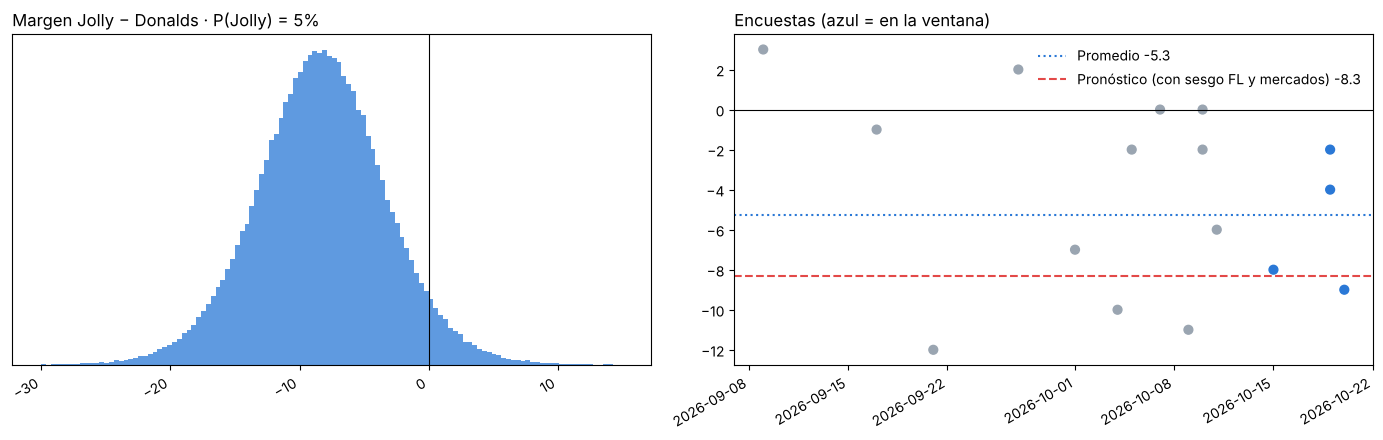

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
s = r['simulacion']
ax[0].hist(s.Margen, bins=120, range=(-30, 15), color='#2a78d6', alpha=.75, density=True)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title(f"Margen Jolly − Donalds · P(Jolly) = {f['P_Jolly']:.0%}", loc='left'); ax[0].set_yticks([])
x = e.copy(); x['fin'] = pd.to_datetime(x.fin)
ax[1].scatter(x.fin, x.margin_poll, c=np.where(x.en_ventana, '#2a78d6', '#9aa5b1'), s=40)
ax[1].axhline(0, color='k', lw=.8); ax[1].axhline(r['margen_encuestas'], ls=':', color='#2a78d6', label=f"Promedio {r['margen_encuestas']:+.1f}")
ax[1].axhline(f['margen_media'], ls='--', color='#e34948', label=f"Pronóstico (con sesgo FL y mercados) {f['margen_media']:+.1f}")
ax[1].legend(frameon=False); ax[1].set_title('Encuestas (azul = en la ventana)', loc='left'); fig.autofmt_xdate(); fig.tight_layout()

## Escenarios de sensibilidad

In [5]:
esc = r['escenarios'].copy()
for c in esc.columns:
    if c != 'escenario': esc[c] = esc[c].map(lambda v: tuple(round(x, 1) for x in v) if isinstance(v, tuple) else v)
esc[['escenario','margen_media','sd','IC80_margen','Jolly','Donalds','Terceros','P_Jolly','P_recuento']].round(3)

,escenario,margen_media,sd,IC80_margen,Jolly,Donalds,Terceros,P_Jolly,P_recuento
0,FINAL: encuestas + mercados (Kalshi y Polymarket),-8.311,5.097,"(-14.7, -2.0)",44.823,53.133,2.044,0.050,0.019
1,Solo encuestas (sin mercados),-10.098,5.097,"(-16.4, -3.8)",43.929,54.027,2.044,0.026,0.010
2,Sin sesgo estatal (como Arizona),-5.245,5.107,"(-11.6, 1.1)",46.352,51.597,2.051,0.143,0.045
3,Sesgo estatal sin contraer (-5.42 pp),-10.665,5.113,"(-17.0, -4.3)",43.647,54.312,2.042,0.021,0.009
4,Distribución normal,-10.085,5.112,"(-16.6, -3.5)",43.935,54.020,2.046,0.024,0.011
5,Sin terceros (como Georgia),-10.082,5.115,"(-16.5, -3.7)",44.909,54.991,0.100,0.026,0.010
6,Sin deriva por encuestas viejas,-10.076,5.090,"(-16.4, -3.8)",43.938,54.015,2.047,0.025,0.010
7,Regla literal V11 (última encuesta de cada fir...,-10.065,5.118,"(-16.4, -3.7)",43.945,54.010,2.045,0.026,0.010
8,Ventana 45 días (11 encuestadoras),-9.219,4.113,"(-14.3, -4.1)",44.152,53.371,2.477,0.015,0.007
9,Ventana 60 días (11 encuestadoras),-9.414,4.107,"(-14.5, -4.3)",44.074,53.488,2.438,0.013,0.007


## Kalshi vs Polymarket: ¿son lo mismo?
Niveles muy correlacionados (0.86) pero cambios diarios casi independientes (0.20); diferencia media 2.2 pp. Se promedian, igual que en Arizona.

corr niveles 0.86 · corr cambios diarios 0.20 · dif. absoluta media 2.2 pp
Hoy: Kalshi 22.3% · Polymarket 20.0% · Polymarket por rangos: margen -4.8 (σ 7.2)


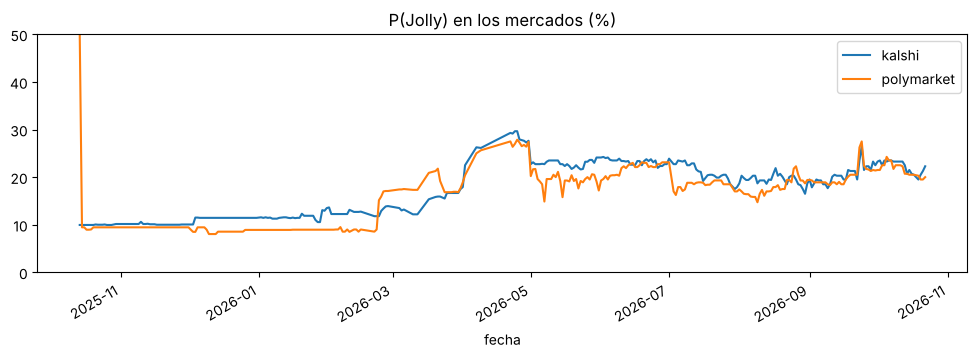

In [6]:
m = pd.read_csv(fm.DATA / 'mercados_fl_gob2026_diario.csv', parse_dates=['fecha']).set_index('fecha')
lg = np.log(m.clip(.01, .99) / (1 - m.clip(.01, .99))).diff().dropna()
print(f"corr niveles {m.corr().iloc[0,1]:.2f} · corr cambios diarios {lg.corr().iloc[0,1]:.2f} · dif. absoluta media {100*(m.kalshi-m.polymarket).abs().mean():.1f} pp")
ax = (100 * m).plot(figsize=(12, 3.5), title='P(Jolly) en los mercados (%)'); ax.set_ylim(0, 50)
mk = r['mercados']; print(f"Hoy: Kalshi {mk['kalshi_D']:.1%} · Polymarket {mk['polymarket_D']:.1%} · Polymarket por rangos: margen {mk['polymarket_rangos_margen_media']:+.1f} (σ {mk['polymarket_rangos_margen_sd']:.1f})")

## Backtest (resumen)
CRPS: menor es mejor. Detalle en `../backtest` (`python backtest_florida.py`).

In [7]:
R = pd.read_csv('../backtest/salida/metricas_margen.csv')
for amb in ('Nacional', 'Nacional_Gob', 'FL_todas', 'FL_2016+'):
    print('\n==', amb); print(R[R.ambito == amb].drop(columns='ambito').sort_values('CRPS').round(3).to_string(index=False))
print('\n== P(variante con menor CRPS que Georgia V11), bootstrap por años')
print(pd.read_csv('../backtest/salida/bootstrap_vs_G.csv').pivot(index='variante', columns='ambito', values='P(variante mejor que G)').round(3).to_string())


== Nacional
                                modelo   n  CRPS   MAE  sesgo  Cob80  Cob95  Brier  sd_media
      G  Georgia V11 (sesgo contraído) 848 3.374 4.662  0.935  0.795  0.952  0.081     6.247
            H6 V11 con vida media 10 d 848 3.380 4.673  0.937  0.800  0.952  0.081     6.247
    H7 V11 con pesos ∝ n (primaria FL) 848 3.386 4.675  0.922  0.801  0.952  0.081     6.269
H3 V11 + cuota R de indecisos estimada 848 3.393 4.669  0.457  0.797  0.948  0.082     6.177
           H4 V11 + Dirichlet y shocks 848 3.410 4.662  0.935  0.838  0.955  0.082     6.444
    H8 V11 sin sesgo estatal (Arizona) 848 3.468 4.811  1.154  0.778  0.956  0.080     6.247
H1 V11 + escenarios de indecisos de AZ 848 3.475 4.771  0.777  0.791  0.945  0.081     6.289
     F1 V11 sesgo estatal sin contraer 848 3.502 4.830  0.855  0.791  0.941  0.086     6.247
               F3 F2 sin sesgo estatal 848 3.579 4.944  1.098  0.782  0.950  0.081     6.450
  F2 V11 + indecisos de la primaria FL 848 3.581 4.923  1

## Errores históricos de las encuestas en Florida
Promedio V11 sin sesgo a 12 días; positivo = las encuestas sobreestimaron al demócrata.

Pro-D en 18 de 23 contiendas · media +2.79 pp · desde 2018: +5.94 pp


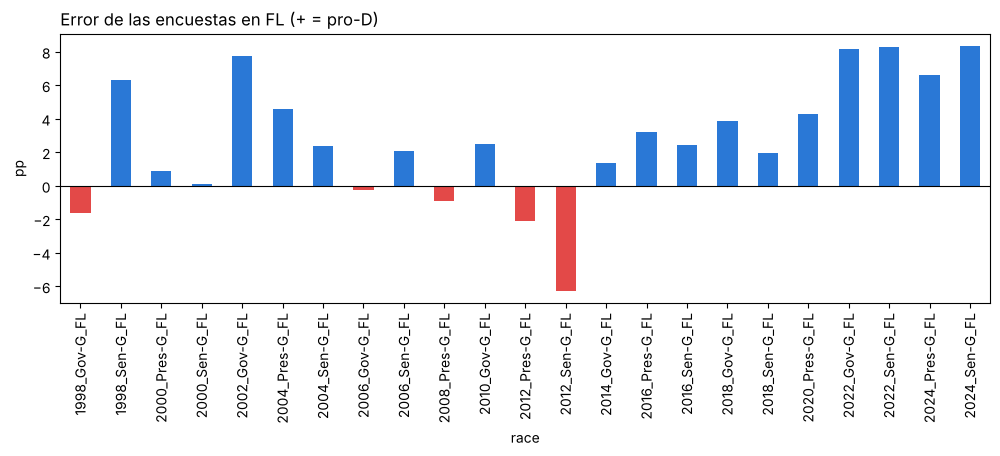

In [8]:
E = pd.read_csv('../backtest/salida/errores_encuestas_FL.csv')
ax = E.plot.bar(x='race', y='error_pp', figsize=(12, 3.5), legend=False, color=np.where(E.error_pp > 0, '#2a78d6', '#e34948'))
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('pp'); ax.set_title('Error de las encuestas en FL (+ = pro-D)', loc='left')
print(f"Pro-D en {int((E.error_pp > 0).sum())} de {len(E)} contiendas · media {E.error_pp.mean():+.2f} pp · desde 2018: {E[E.year >= 2018].error_pp.mean():+.2f} pp")

## Voto anticipado (civicAPI · diagnóstico) y electorado

In [9]:
va = r['voto_anticipado']
print(f"{va['estado']} · al {va['fecha']}: {va['emitidos']:,} votos emitidos ({va['por_correo']:,} por correo, {va['en_persona']:,} en persona)")
print(f"D {va['pct_D']:.1f}% · R {va['pct_R']:.1f}% · NPA {va['pct_NPA']:.1f}% · otros {va['pct_Otros']:.1f}% → D−R {va['margen_DR_pp']:+.1f} pp (correo {va['margen_DR_correo_pp']:+.1f}, en persona {va['margen_DR_persona_pp']:+.1f})")
print('Referencias: 2022 al 31-oct R+3.5 de los votos emitidos (DeSantis ganó por 19.4); 2024 al 21-oct el correo iba D+71 mil (Trump ganó por 13.1).')
display(va['condados'][['condado','emitidos','emitidos_D','emitidos_R','emitidos_NPA','margen_DR_pp']].head(10))
r['diagnostico']

snapshot guardado (ProxyError: HTTPSConnectionPool(host='civicapi.org', port=443): Max retries exceeded with ur) · al 2026-10-22: 1,676,291 votos emitidos (1,124,045 por correo, 552,246 en persona)
D 41.3% · R 38.2% · NPA 18.1% · otros 2.4% → D−R +3.1 pp (correo +6.7, en persona -4.4)
Referencias: 2022 al 31-oct R+3.5 de los votos emitidos (DeSantis ganó por 19.4); 2024 al 21-oct el correo iba D+71 mil (Trump ganó por 13.1).


,condado,emitidos,emitidos_D,emitidos_R,emitidos_NPA,margen_DR_pp
0,Miami-Dade,161442,66276,53808,38362,7.722897
1,Palm Beach,130476,66722,36090,24153,23.477115
2,Broward,111213,63466,24718,20800,34.841251
3,Hillsborough,110060,47584,39429,20453,7.409595
4,Pinellas,107347,43092,40860,20768,2.079238
5,Orange,96288,48306,26517,19263,22.628988
6,Lee,95733,27866,46829,18600,-19.808217
7,Sarasota,65529,25626,26930,11299,-1.989959
8,Brevard,64054,22418,28710,11128,-9.822962
9,Volusia,54086,20131,22456,9882,-4.298709


,indicador,valor,fecha,fuente
0,registro_republicanos,5690000,2026-10-05,Florida DOS (cierre de registro para la genera...
1,registro_democratas,4150000,2026-10-05,Florida DOS vía WLRN
2,registro_sin_partido_NPA,3350000,2026-10-05,Florida DOS vía WLRN
3,registro_otros_partidos,442000,2026-10-05,Florida DOS vía WLRN (Independent Party ~331 m...
4,registro_total,13700000,2026-10-05,Florida DOS vía WLRN
5,ventaja_registro_R,1540000,2026-10-05,Florida DOS vía WLRN
6,primaria_R_votos,1696029,2026-08-18,Resultados preliminares (Excel del usuario)
7,primaria_D_votos,1249352,2026-08-18,Resultados preliminares (Excel del usuario)
8,voto_anticipado_2022_R_al_31oct,1173000,2022-10-31,Florida DOS vía FOX 35
9,voto_anticipado_2022_D_al_31oct,1077000,2022-10-31,Florida DOS vía FOX 35
